In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore') # Suppress potential warnings for cleaner output


# Set a random seed for reproducibility of results
np.random.seed(42)


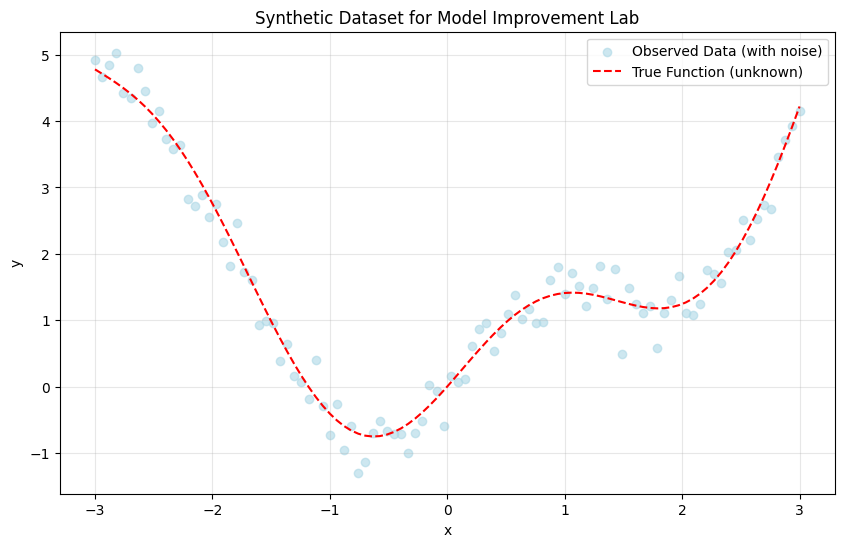

In [2]:
# --- Generating Synthetic Data ---
# Define the true underlying function (unknown to the model)
def true_function(x):
    """
    The hidden function that generates the true relationship between x and y.
    This represents the 'real' energy demand pattern over time.
    """
    return 0.5 * x**2 + np.sin(2 * x)


# Generate data points
x_min, x_max = -3, 3 # Define the range of x values
n_samples = 100      # Number of data points to generate
X_raw = np.linspace(x_min, x_max, n_samples).reshape(-1, 1) # Create evenly spaced x values
y_true = true_function(X_raw) # Calculate the true y values based on the function


# Add Gaussian noise to simulate real-world observations
noise_level = 0.3 # Standard deviation of the noise
noise = np.random.normal(0, noise_level, size=y_true.shape) # Generate random noise
y_observed = y_true + noise # Observed y values are true values plus noise


# Plot the generated data
plt.figure(figsize=(10, 6))
plt.scatter(X_raw, y_observed, alpha=0.6, label='Observed Data (with noise)', color='lightblue')
plt.plot(X_raw, y_true, color='red', linestyle='--', label='True Function (unknown)')
plt.title('Synthetic Dataset for Model Improvement Lab')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [3]:
# --- Splitting the Data ---
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_observed, test_size=0.3, random_state=42
)


print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")


Training set size: 70
Test set size: 30


Fitting model with degree 1...
Fitting model with degree 2...
Fitting model with degree 5...
Fitting model with degree 10...
Fitting model with degree 15...


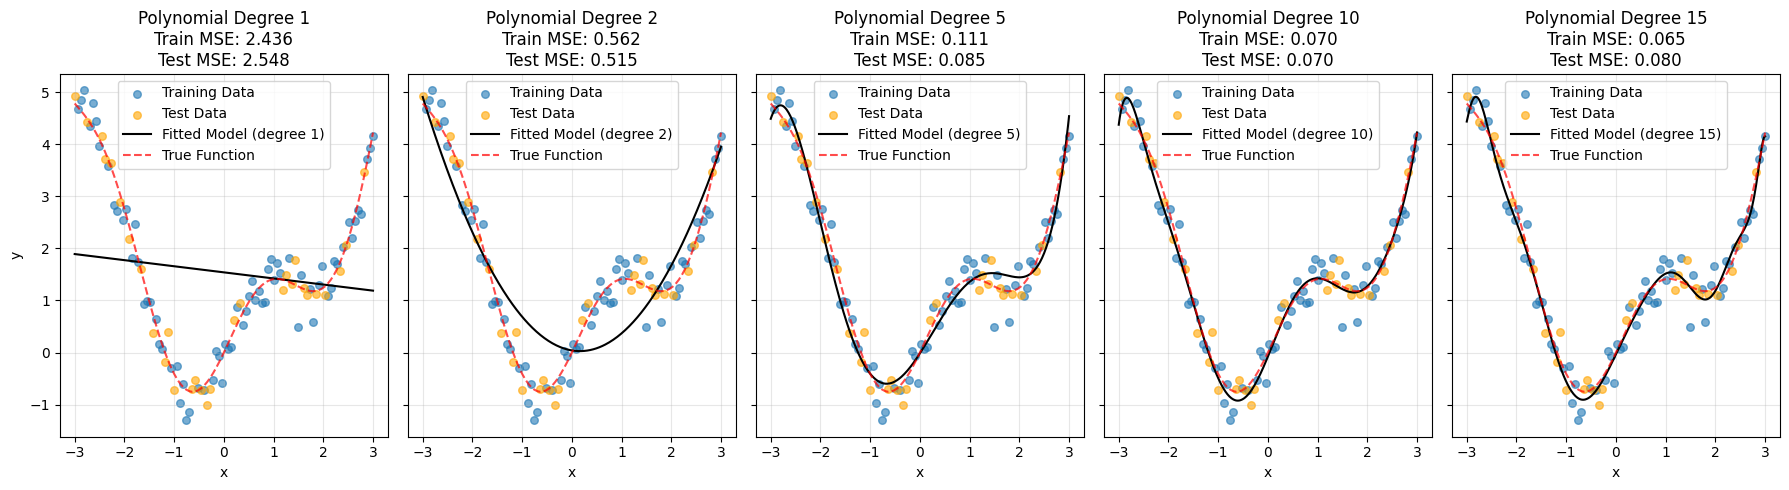

In [6]:
# --- Defining Degrees to Compare ---
degrees = [1, 2, 5, 10, 15] # Degree 1 (linear) -> Underfit, Degree 2 (quadratic) -> Good, Degree 15 -> Overfit
models = {}
predictions = {}
train_mse = {}
test_mse = {}


# --- Loop through each degree to fit models ---
for degree in degrees:
    # Create a pipeline: Polynomial Features -> Linear Regression
    # This ensures that the polynomial transformation is applied correctly
    # within the training process, preventing data leakage.
    # This is crucial for correct model evaluation.
    model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=degree)),
        ("linear_regression", LinearRegression())
    ])
    
    # Fit the model on the training data
    print(f"Fitting model with degree {degree}...")
    model.fit(X_train, y_train)
    
    # Store the trained model
    models[degree] = model
    
    # Make predictions on both training and test sets
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    predictions[degree] = (y_train_pred, y_test_pred)
    
    # Calculate Mean Squared Error (MSE) for both sets
    # MSE is a common metric for regression, measuring average squared differences.
    train_mse[degree] = mean_squared_error(y_train, y_train_pred)
    test_mse[degree] = mean_squared_error(y_test, y_test_pred)


# --- Plotting the Results for Each Degree ---
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=True)


for i, degree in enumerate(degrees):
    ax = axes[i]
    
    # Plot the original data points (training and test)
    ax.scatter(X_train, y_train, alpha=0.6, label='Training Data', s=30)
    ax.scatter(X_test, y_test, alpha=0.6, label='Test Data', s=30, color='orange')
    
    # Plot the model's prediction over the full range of x
    # This helps visualize the model's behavior, especially for high-degree polynomials.
    X_plot = np.linspace(x_min, x_max, 300).reshape(-1, 1)
    y_plot_pred = models[degree].predict(X_plot)
    ax.plot(X_plot, y_plot_pred, color='black', label=f'Fitted Model (degree {degree})')
    
    # Plot the true function for reference
    ax.plot(X_raw, y_true, color='red', linestyle='--', label='True Function', alpha=0.7)
    
    ax.set_title(f'Polynomial Degree {degree}\nTrain MSE: {train_mse[degree]:.3f}\nTest MSE: {test_mse[degree]:.3f}')
    ax.set_xlabel('x')
    if i == 0:
        ax.set_ylabel('y')
    ax.legend()
    ax.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()


In [7]:
# --- Define Regularization Parameters to Test ---
alphas = [0.001, 0.1, 1, 10]


# --- Ridge Regression ---
print("--- Ridge (L2) Regularization ---")
for alpha in alphas:
    ridge_model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=15)),
        ("regression", Ridge(alpha=alpha))
    ])
    
    ridge_model.fit(X_train, y_train)
    
    y_train_pred = ridge_model.predict(X_train)
    y_test_pred = ridge_model.predict(X_test)
    
    train_mse_ridge = mean_squared_error(y_train, y_train_pred)
    test_mse_ridge = mean_squared_error(y_test, y_test_pred)
    
    print(f"Ridge (alpha={alpha}): Train MSE = {train_mse_ridge:.4f}, Test MSE = {test_mse_ridge:.4f}")


# --- Lasso Regression ---
print("\n--- Lasso (L1) Regularization ---")
for alpha in alphas:
    lasso_model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=15)),
        ("regression", Lasso(alpha=alpha, max_iter=10000)) # Increase max_iter to avoid convergence warnings
    ])
    
    lasso_model.fit(X_train, y_train)
    
    y_train_pred = lasso_model.predict(X_train)
    y_test_pred = lasso_model.predict(X_test)
    
    train_mse_lasso = mean_squared_error(y_train, y_train_pred)
    test_mse_lasso = mean_squared_error(y_test, y_test_pred)
    
    print(f"Lasso (alpha={alpha}): Train MSE = {train_mse_lasso:.4f}, Test MSE = {test_mse_lasso:.4f}")


--- Ridge (L2) Regularization ---
Ridge (alpha=0.001): Train MSE = 0.0649, Test MSE = 0.0797
Ridge (alpha=0.1): Train MSE = 0.0657, Test MSE = 0.0792
Ridge (alpha=1): Train MSE = 0.0765, Test MSE = 0.0959
Ridge (alpha=10): Train MSE = 0.1477, Test MSE = 0.1441

--- Lasso (L1) Regularization ---
Lasso (alpha=0.001): Train MSE = 0.0705, Test MSE = 0.0844
Lasso (alpha=0.1): Train MSE = 0.2395, Test MSE = 0.2042
Lasso (alpha=1): Train MSE = 0.4513, Test MSE = 0.4856
Lasso (alpha=10): Train MSE = 0.5326, Test MSE = 0.6572


Unreg shape: (16,)
Ridge shape: (16,)
Lasso shape: (16,)


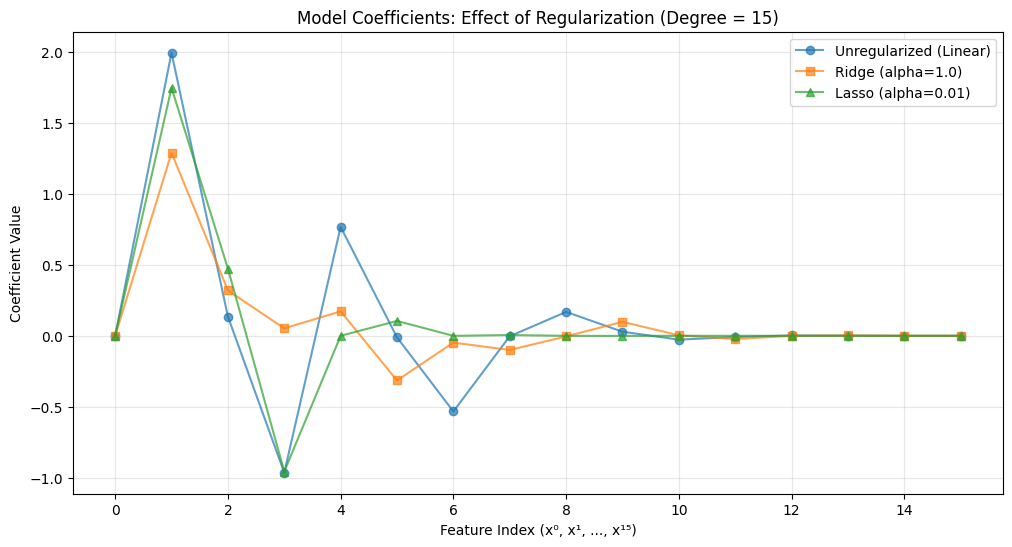

In [8]:
# Fit models (all with degree=15 in a Pipeline)
degree = 15


model_unreg = Pipeline([('poly', PolynomialFeatures(degree=degree)), ('lin', LinearRegression())])
model_ridge = Pipeline([('poly', PolynomialFeatures(degree=degree)), ('ridge', Ridge(alpha=1.0))])
model_lasso = Pipeline([('poly', PolynomialFeatures(degree=degree)), ('lasso', Lasso(alpha=0.01, max_iter=10000))])


model_unreg.fit(X_train, y_train)
model_ridge.fit(X_train, y_train)
model_lasso.fit(X_train, y_train)


# Extract and ensure 1D coefficients
coeffs_unreg = model_unreg.named_steps['lin'].coef_.ravel()
coeffs_ridge = model_ridge.named_steps['ridge'].coef_.ravel()
coeffs_lasso = model_lasso.named_steps['lasso'].coef_.ravel()


# Debug shapes
print("Unreg shape:", coeffs_unreg.shape)   # Should be (16,)
print("Ridge shape:", coeffs_ridge.shape)   # Should be (16,)
print("Lasso shape:", coeffs_lasso.shape)   # Should be (16,)


# Now safe to plot
feature_indices = np.arange(len(coeffs_unreg))


plt.figure(figsize=(12, 6))
plt.plot(feature_indices, coeffs_unreg, 'o-', label='Unregularized (Linear)', alpha=0.7)
plt.plot(feature_indices, coeffs_ridge, 's-', label='Ridge (alpha=1.0)', alpha=0.7)
plt.plot(feature_indices, coeffs_lasso, '^-', label='Lasso (alpha=0.01)', alpha=0.7)


plt.title('Model Coefficients: Effect of Regularization (Degree = 15)')
plt.xlabel('Feature Index (x⁰, x¹, ..., x¹⁵)')
plt.ylabel('Coefficient Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()



--- Cross-Validation for Polynomial Degree ---


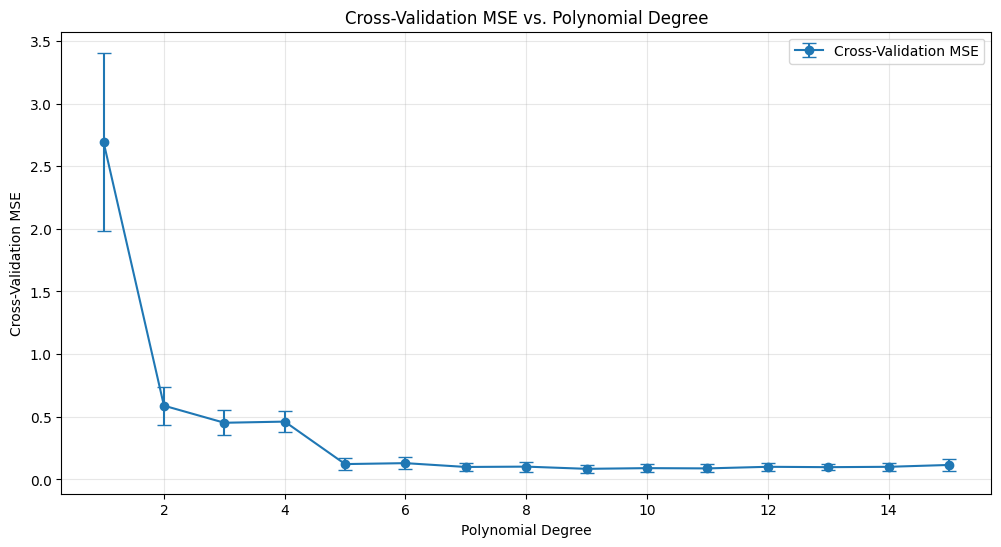

Best degree based on CV: 9 (CV MSE: 0.0847)


In [9]:
# --- CV for Polynomial Degree ---
print("\n--- Cross-Validation for Polynomial Degree ---")
degrees_to_test = range(1, 16) # Test degrees from 1 to 15
cv_scores_mean = []
cv_scores_std = []


for degree in degrees_to_test:
    # Create the model pipeline for this degree
    model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=degree)),
        ("regression", LinearRegression())
    ])
    
    # Perform 5-fold cross-validation on the training set only
    # This simulates the process of having "unseen" data during model selection.
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    # cross_val_score returns negative MSE, so we convert back to positive MSE
    cv_mse_scores = -cv_scores
    
    cv_scores_mean.append(cv_mse_scores.mean())
    cv_scores_std.append(cv_mse_scores.std())


# Plot CV error vs. degree
plt.figure(figsize=(12, 6))
plt.errorbar(degrees_to_test, cv_scores_mean, yerr=cv_scores_std, marker='o', capsize=5, label='Cross-Validation MSE')
plt.title('Cross-Validation MSE vs. Polynomial Degree')
plt.xlabel('Polynomial Degree')
plt.ylabel('Cross-Validation MSE')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# Find the degree with the lowest CV error
best_degree_idx = np.argmin(cv_scores_mean)
best_degree_from_cv = degrees_to_test[best_degree_idx]
print(f"Best degree based on CV: {best_degree_from_cv} (CV MSE: {cv_scores_mean[best_degree_idx]:.4f})")



--- Cross-Validation for Ridge Alpha ---


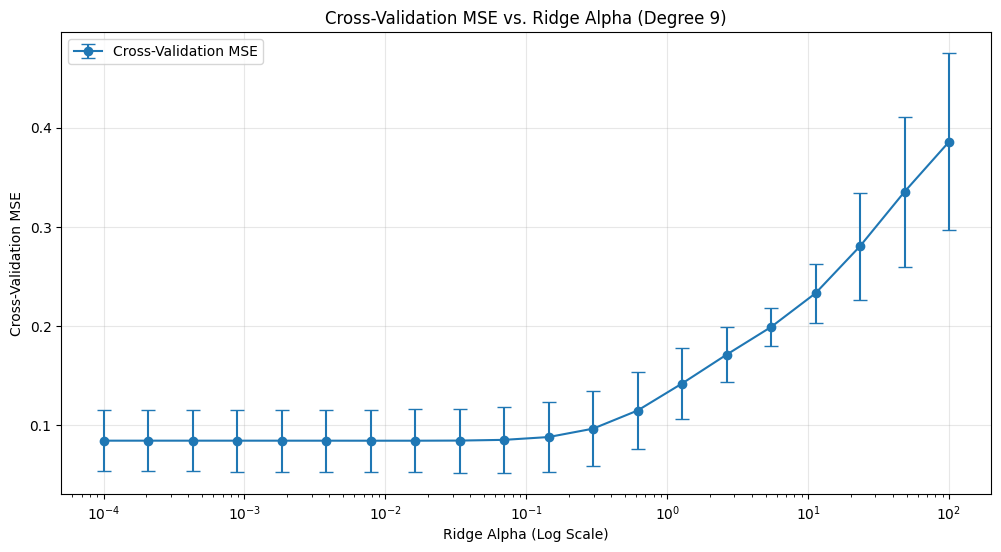

Best alpha based on CV: 0.0078 (CV MSE: 0.0847)


In [10]:
# --- CV for Ridge Alpha ---
print("\n--- Cross-Validation for Ridge Alpha ---")
# Define a range of alpha values to test (logarithmically spaced for better coverage)
alphas_to_test = np.logspace(-4, 2, 20) # e.g., [0.0001, ..., 100]


cv_scores_ridge_mean = []
cv_scores_ridge_std = []


# Use the best degree found from the previous CV step
best_degree_for_ridge_cv = best_degree_from_cv


for alpha in alphas_to_test:
    # Create the model pipeline with the fixed best degree and current alpha
    model = Pipeline([
        ("poly_features", PolynomialFeatures(degree=best_degree_for_ridge_cv)),
        ("regression", Ridge(alpha=alpha))
    ])
    
    # Perform 5-fold CV on the training set for this specific alpha
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
    cv_mse_scores = -cv_scores
    
    cv_scores_ridge_mean.append(cv_mse_scores.mean())
    cv_scores_ridge_std.append(cv_mse_scores.std())


# Plot CV error vs. alpha
plt.figure(figsize=(12, 6))
plt.errorbar(alphas_to_test, cv_scores_ridge_mean, yerr=cv_scores_ridge_std, marker='o', capsize=5, label='Cross-Validation MSE')
plt.xscale("log") # Use a log scale for alpha on the x-axis for better visualization
plt.title(f'Cross-Validation MSE vs. Ridge Alpha (Degree {best_degree_for_ridge_cv})')
plt.xlabel('Ridge Alpha (Log Scale)')
plt.ylabel('Cross-Validation MSE')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


# Find the alpha with the lowest CV error
best_alpha_idx = np.argmin(cv_scores_ridge_mean)
best_alpha_from_cv = alphas_to_test[best_alpha_idx]
print(f"Best alpha based on CV: {best_alpha_from_cv:.4f} (CV MSE: {cv_scores_ridge_mean[best_alpha_idx]:.4f})")


In [11]:
print("\n--- Nested Cross-Validation Example ---")
print("This estimates the generalization error of the *entire* model selection process.")
print("Outer loop: Estimate generalization error")
print("Inner loop: Select best hyperparameters (degree and alpha)")


# Define the outer CV loop (for final performance estimation)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)
nested_scores = []


# Define the range of hyperparameters to search in the inner loop
degrees_inner = range(1, 8)  # Reduced range for efficiency in this example
alphas_inner = [0.001, 0.01, 0.1, 1, 10]


for fold_idx, (train_idx, val_idx) in enumerate(outer_cv.split(X_train)):
    print(f"  Processing outer fold {fold_idx+1}...")
    # Split the main training data into inner train and inner validation (val) sets
    X_train_outer_fold, X_val_outer_fold = X_train[train_idx], X_train[val_idx]
    y_train_outer_fold, y_val_outer_fold = y_train[train_idx], y_train[val_idx]


    # --- Inner CV Loop: Hyperparameter Tuning ---
    best_score_inner = float('inf')
    best_params_inner = {}
    
    for degree in degrees_inner:
        for alpha in alphas_inner:
            model = Pipeline([
                ("poly_features", PolynomialFeatures(degree=degree)),
                ("regression", Ridge(alpha=alpha))
            ])
            # Perform 3-fold CV on the *inner* training set to evaluate this (degree, alpha) combo
            inner_cv_scores = cross_val_score(model, X_train_outer_fold, y_train_outer_fold, cv=3, scoring='neg_mean_squared_error')
            mean_inner_score = -inner_cv_scores.mean() # Convert back to positive MSE
            
            # Keep track of the best (degree, alpha) found in this inner loop
            if mean_inner_score < best_score_inner:
                best_score_inner = mean_inner_score
                best_params_inner = {'degree': degree, 'alpha': alpha}


    # --- Final Model Training and Evaluation (using best inner params) ---
    # Now that we've found the best params for *this* outer fold, train the final model
    # on the *entire* inner training set using those best params.
    final_model_nested = Pipeline([
        ("poly_features", PolynomialFeatures(degree=best_params_inner['degree'])),
        ("regression", Ridge(alpha=best_params_inner['alpha']))
    ])
    final_model_nested.fit(X_train_outer_fold, y_train_outer_fold)


    # Evaluate this final model on the inner validation set (which is part of the outer CV's test fold)
    # This gives us an unbiased estimate of performance for this specific outer fold.
    y_pred_nested = final_model_nested.predict(X_val_outer_fold)
    fold_score = mean_squared_error(y_val_outer_fold, y_pred_nested)
    nested_scores.append(fold_score)


print(f"\nNested CV MSE scores for each outer fold: {[f'{s:.4f}' for s in nested_scores]}")
print(f"Mean Nested CV MSE: {np.mean(nested_scores):.4f} (+/- {np.std(nested_scores) * 2:.4f})")
print(f"This mean score is an estimate of the true generalization error for the model selection process.")



--- Nested Cross-Validation Example ---
This estimates the generalization error of the *entire* model selection process.
Outer loop: Estimate generalization error
Inner loop: Select best hyperparameters (degree and alpha)
  Processing outer fold 1...
  Processing outer fold 2...
  Processing outer fold 3...
  Processing outer fold 4...
  Processing outer fold 5...

Nested CV MSE scores for each outer fold: ['0.1158', '0.1106', '0.0652', '0.1234', '0.2199']
Mean Nested CV MSE: 0.1270 (+/- 0.1015)
This mean score is an estimate of the true generalization error for the model selection process.



--- Training Final Model with Best CV Parameters ---
Best Degree (from CV): 9
Best Alpha (from CV): 0.0078

--- Final Model Performance on Test Set ---
Final Test MSE: 0.0639


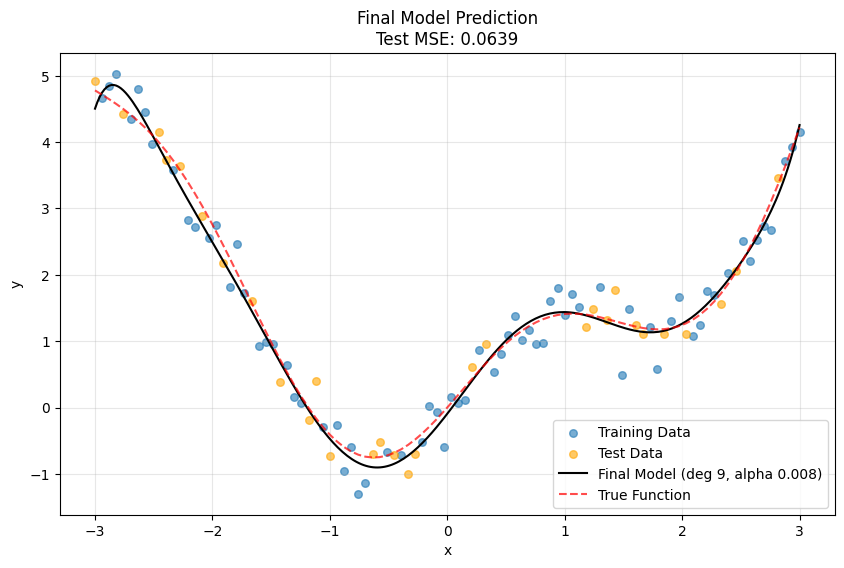


--- Summary ---
This lab demonstrated the core concepts of Topic 4:
1. Bias-Variance Tradeoff: Observed via underfitting (degree 1) and overfitting (degree 15).
2. Regularization: Applied Ridge/Lasso to control complexity and reduce overfitting.
3. Cross-Validation: Used to select hyperparameters (degree, alpha) without using the test set.
4. Final Evaluation: Assessed the final model's generalization performance on the test set.
The process followed the universal machine learning workflow: data splitting, model training,
hyperparameter tuning (with CV), and final evaluation, ensuring robust and generalizable models.


In [12]:
# --- Train Final Model with Best Parameters Found via CV ---
print("\n--- Training Final Model with Best CV Parameters ---")
print(f"Best Degree (from CV): {best_degree_from_cv}")
print(f"Best Alpha (from CV): {best_alpha_from_cv:.4f}")


final_model = Pipeline([
    ("poly_features", PolynomialFeatures(degree=best_degree_from_cv)),
    ("regression", Ridge(alpha=best_alpha_from_cv))
])


# Train on the *entire* training set (X_train, y_train)
final_model.fit(X_train, y_train)


# --- Evaluate Final Model on the Held-Out Test Set ---
y_test_pred_final = final_model.predict(X_test)
test_mse_final = mean_squared_error(y_test, y_test_pred_final)


print(f"\n--- Final Model Performance on Test Set ---")
print(f"Final Test MSE: {test_mse_final:.4f}")


# --- Visualize the Final Model's Predictions ---
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, alpha=0.6, label='Training Data', s=30)
plt.scatter(X_test, y_test, alpha=0.6, label='Test Data', s=30, color='orange')


# Plot the final model's prediction curve
X_plot = np.linspace(x_min, x_max, 300).reshape(-1, 1)
y_plot_pred_final = final_model.predict(X_plot)
plt.plot(X_plot, y_plot_pred_final, color='black', label=f'Final Model (deg {best_degree_from_cv}, alpha {best_alpha_from_cv:.3f})')


# Plot the true function for comparison
plt.plot(X_raw, y_true, color='red', linestyle='--', label='True Function', alpha=0.7)


plt.title(f'Final Model Prediction\nTest MSE: {test_mse_final:.4f}')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


print("\n--- Summary ---")
print("This lab demonstrated the core concepts of Topic 4:")
print("1. Bias-Variance Tradeoff: Observed via underfitting (degree 1) and overfitting (degree 15).")
print("2. Regularization: Applied Ridge/Lasso to control complexity and reduce overfitting.")
print("3. Cross-Validation: Used to select hyperparameters (degree, alpha) without using the test set.")
print("4. Final Evaluation: Assessed the final model's generalization performance on the test set.")
print("The process followed the universal machine learning workflow: data splitting, model training,")
print("hyperparameter tuning (with CV), and final evaluation, ensuring robust and generalizable models.")
